# **Resolución Punto 2.a del Parcial 1 - Introducción a la Teoría de la Computación**

# **Fundamento teórico**


Un Autómata Finito Determinista se define formalmente como una 5-tupla:
M=(Q, Σ, δ, q0, F) \
Donde:


*   Q  Conjunto finito de estados
*   Σ Alfabeto de entrada (en este caso Σ={0,1})
*   δ: Q×Σ→ Q Función de transición
*   q0 ∈ Q Estado inicial
*   F ⊆ Q Conjunto de estados de aceptación (estados finales)

El autómata acepta una cadena w=w1w2⋯wn
si existe una secuencia de estados r0, r1, …, rn​ tal que:



1.   r0 = q0
2.   ri = δ(ri-1, wi) para todo i ∈ {1, …, n} (Equivalente a la notación: ri+1 = δ(ri, wi+1) para todo i ∈ {1, …, n-1})
3.   rn ​∈ F

La lógica del código se basa en guardar en memoria esta secuencia de estados creado por la cadena w, suponiendo r0 = q0, ri = δ(ri-1, wi) para todo i ∈ {1, …, n} y verificando que se cumpla rn ​∈ F.

Si ocurre eso, la salida será: "w es aceptada por M", por le contrario, imprimirá: "w no es aceptada por M"

# **Características de la entrada**



El DFA tiene un formato de un DataFrame guardado en un archivo csv, la cadena es un archivo de texto, por ende utilizamos la librería **pandas** para manipular la información del DataFrame.

Se utilizarán los siguientes ejemplos para analizar el funcionamiento del código. Guardados en [Google Drive](https://drive.google.com/drive/folders/1JpXI7vnLV4uLgv6PoMQxX_Zrvd7K7Tr4?usp=drive_link)


***DFA***

* DFA(1): Cadenas que terminan en 1 \
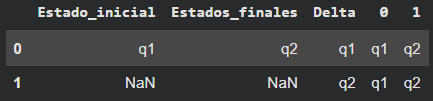
* DFA(2): Contiene 10110 como subcadena \
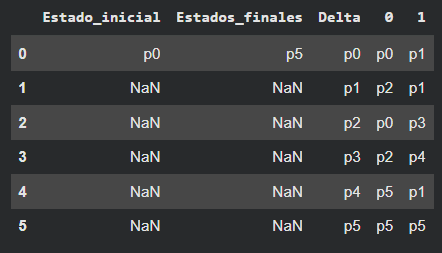
* DFA(3): Autómata que acepta los números binario divisible por 3 \
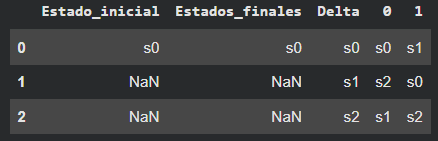

***Cadenas***

1.   Cadena de la forma: 9998 ceros + 01
2.   Cadena de la forma: 9995 ceros + 10110
3.   Cadena de la forma: 10000 ceros

In [ ]:
import pandas as pd

La entrada se lee de la siguiente manera:

*   **M** es el DFA en formato DataFrame.
*   **w** es un variable del tipo string.
*   **delta** es un DataFrame agregado a conveniencia de la notación usada en el pseudocódigo.

## **DFA**

In [ ]:
M = pd.read_csv("DFA(1).csv")
M

,Estado_inicial,Estados_finales,Delta,0,1
0,q1,q2,q1,q1,q2
1,NaN,NaN,q2,q1,q2


In [ ]:
M = pd.read_csv("DFA(2).csv")
M

In [ ]:
M = pd.read_csv("DFA(3).csv")
M

In [ ]:
delta = M.iloc[:, 2:].set_index("Delta")
delta

,0,1
Delta,,
q1,q1,q2
q2,q1,q2


## **Cadenas**

In [ ]:
with open("cadena(1).txt", "r", encoding="utf-8") as f:
    w = f.read()

In [ ]:
with open("cadena(2).txt", "r", encoding="utf-8") as f:
    w = f.read()

In [ ]:
with open("cadena(3).txt", "r", encoding="utf-8") as f:
    w = f.read()

# **Código**

In [ ]:
n = len(w)
q0 = M.loc[0, "Estado_inicial"]
r = [q0]

for i in range(1, n+1):
  estado_i = delta.loc[str(r[i-1]), w[i-1]]
  r.append(estado_i) #  Forma del código en la notación r[i] = M[r[i-1], w[i-1]].

if r[n] in M["Estados_finales"].values:
  print("w es aceptada por M")
else:
  print("w no es aceptada por M")

w es aceptada por M


# **Resultados**



* Para la cadena(1) es aceptada unícamente por DFA(1).
* Para la cadena(2) es aceptada unícamente por DFA(2).
* Para la cadena(3) es aceptada unícamente por DFA(3).

## **Ejemplo de uso**
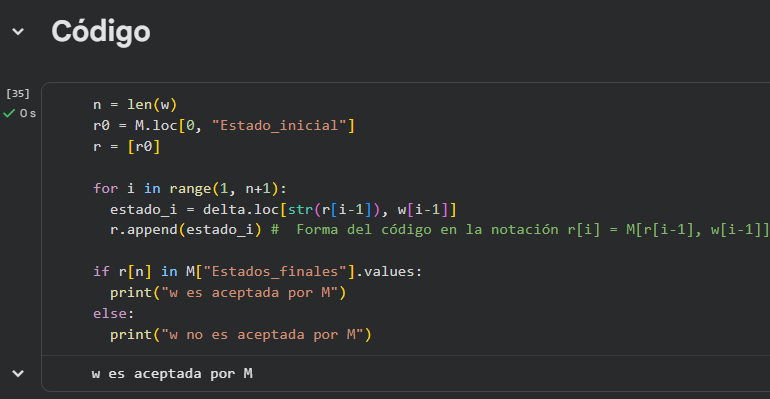

## **Conclusión**
La simulación de un Autómata Finito Determinista (DFA) sobre una cadena de entrada w tiene una complejidad temporal de O(n), donde n = |w| es la longitud de la cadena. Esto se debe a que el algoritmo realiza exactamente nn
n transiciones, una por cada símbolo leído, y cada consulta a la función de transición δ se ejecuta en tiempo constante O(1).

Una consecuencia notable de este resultado es que la cantidad de estados del autómata no influye en la complejidad temporal de la simulación. Esto cobra especial relevancia al considerar la construcción de subconjuntos, mediante la cual a partir de cualquier Autómata Finito No Determinista (NFA) con k estados se puede construir un DFA equivalente con hasta 2^k estados. A pesar de esta explosión exponencial en el número de estados, la complejidad de simulación del DFA resultante sigue siendo O(n).

Por lo tanto, convertir un NFA en un DFA y simularlo con este algoritmo garantiza un reconocimiento de cadenas en tiempo lineal, independientemente de la complejidad estructural del autómata original. Esto hace de la simulación de DFAs una herramienta computacionalmente eficiente y robusta.